Mengunduh data BTC-USD...


[*********************100%***********************]  1 of 1 completed

Price              Close          High           Low          Open  \
Ticker           BTC-USD       BTC-USD       BTC-USD       BTC-USD   
Date                                                                 
2021-05-03  58232.316406  59210.882812  56482.003906  58877.390625   
2021-05-10  46456.058594  59519.355469  43963.351562  58250.871094   
2021-05-17  34770.582031  46623.558594  30681.496094  46415.898438   
2021-05-24  35678.128906  40782.078125  33520.738281  34700.363281   
2021-05-31  35862.378906  39478.953125  34241.945312  35658.593750   
...                  ...           ...           ...           ...   
2026-04-06  70753.406250  73784.234375  67740.507812  68982.914062   
2026-04-13  73856.351562  78320.679688  70588.523438  70757.617188   
2026-04-20  78657.539062  79468.000000  73775.570312  73854.250000   
2026-04-27  78538.226562  79488.171875  74958.570312  78661.015625   
2026-05-04  80395.679688  82792.210938  78217.960938  78540.289062   

Price             V

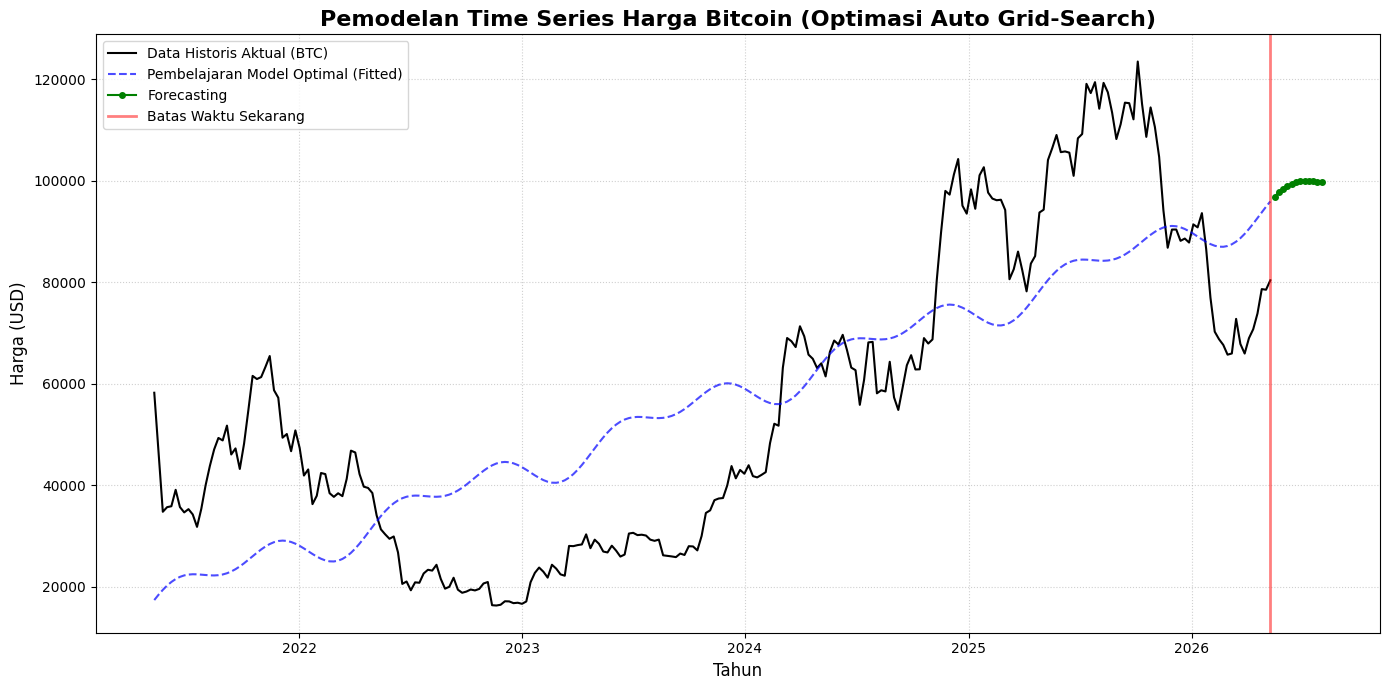

In [10]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import warnings

# Mengabaikan warning agar output console lebih bersih
warnings.filterwarnings('ignore')

# ==========================================
# 1. PENGAMBILAN & PREPROCESSING DATA
# ==========================================
print("Mengunduh data BTC-USD...")
df = yf.download('BTC-USD', period='5y', interval='1wk')
print(df)

# Resample frekuensi menjadi mingguan (W) dan forward fill jika ada nilai kosong
df = df.resample('W').ffill()

# ==========================================
# 2. OPTIMASI PARAMETER (GRID SEARCH)
# ==========================================
print("\nMulai mencari orde optimal (Grid Search)...")

# Menentukan batas data latih (80%) dan data uji (20%)
ukuran_train = int(len(df) * 0.8)
y_train = df['Close'].iloc[:ukuran_train]
y_test = df['Close'].iloc[ukuran_train:]

# Variabel untuk menyimpan hasil terbaik
mae_terbaik = float('inf')
kombinasi_terbaik = {'trend_order': 0, 'fourier_order': 0}
X_fitur_terbaik = None
dp_terpadu_terbaik = None

# Looping mencari kombinasi terbaik
for t_order in range(1, 4):       # Mencoba Tren Orde 1 (Linear) sampai 3 (Kubik)
    for f_order in range(1, 15):  # Mencoba Fourier Orde 1 sampai 14
        
        # Buat Fourier dan Deterministic Process
        fourier_terms = Fourier(period=52, order=f_order) # period=52 karena 1 tahun = 52 minggu
        dp_uji = DeterministicProcess(
            index=df.index,
            constant=True,
            order=t_order,
            additional_terms=[fourier_terms],
            drop=True
        )
        
        # Buat matriks fitur
        X_fitur_uji = dp_uji.in_sample()
        
        # Bagi fitur menjadi Train dan Test
        X_train = X_fitur_uji.iloc[:ukuran_train]
        X_test = X_fitur_uji.iloc[ukuran_train:]
        
        # Latih Model
        model_uji = LinearRegression(fit_intercept=False)
        model_uji.fit(X_train, y_train)
        
        # Evaluasi Model
        prediksi_uji = model_uji.predict(X_test)
        error_mae = mean_absolute_error(y_test, prediksi_uji)
        
        # Simpan jika MAE ini lebih rendah dari yang sebelumnya
        if error_mae < mae_terbaik:
            mae_terbaik = error_mae
            kombinasi_terbaik = {'trend_order': t_order, 'fourier_order': f_order}
            X_fitur_terbaik = X_fitur_uji
            dp_terpadu_terbaik = dp_uji

print("\n=== Hasil Optimasi Parameter ===")
print(f"Tren Orde Terbaik    : {kombinasi_terbaik['trend_order']}")
print(f"Fourier Orde Terbaik : {kombinasi_terbaik['fourier_order']}")
print(f"MAE Terendah         : {mae_terbaik:.2f}")

# ==========================================
# 3. PELATIHAN MODEL FINAL & FORECASTING
# ==========================================
# Latih ulang model menggunakan KESELURUHAN DATA dengan parameter terbaik
model_final = LinearRegression(fit_intercept=False)
model_final.fit(X_fitur_terbaik, df['Close'])

# Forecasting ke masa depan (12 minggu)
horizon_masa_depan = 12
X_masa_depan = dp_terpadu_terbaik.out_of_sample(steps=horizon_masa_depan)
prediksi_masa_depan = model_final.predict(X_masa_depan).ravel()

# Menyimpan hasil prediksi ke dalam DataFrame
df_hasil_forecast = pd.DataFrame({
    'prediksi': np.round(prediksi_masa_depan, 0)
}, index=X_masa_depan.index)

print("\n=== Hasil Forecasting (12 Minggu Kedepan) ===")
print(df_hasil_forecast)

# ==========================================
# 4. VISUALISASI KESELURUHAN
# ==========================================
plt.figure(figsize=(14, 7))

# Plot Data Historis Aktual
plt.plot(df.index, 
         df['Close'], 
         color='black', label='Data Historis Aktual (BTC)')

# Plot Garis Fit Model (Pembelajaran Masa Lalu)
plt.plot(X_fitur_terbaik.index, model_final.predict(X_fitur_terbaik), 
         color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model Optimal (Fitted)')

# Plot Forecasting Masa Depan
plt.plot(df_hasil_forecast.index, df_hasil_forecast['prediksi'], 
         color='green', marker='o', markersize=4, label='Forecasting')

# Estetika Grafik
plt.axvline(x=df.index[-1], color='red', 
            linestyle='-', linewidth=2, alpha=0.5, label='Batas Waktu Sekarang')

plt.title('Pemodelan Time Series Harga Bitcoin (Optimasi Auto Grid-Search)', fontsize=16, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga (USD)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

Mengunduh data BTC-USD...


[*********************100%***********************]  1 of 1 completed



Mulai mencari orde optimal (Grid Search)...

=== Hasil Optimasi Parameter (Termasuk Volume) ===
Tren Orde Terbaik    : 1
Fourier Orde Terbaik : 1
MAE Terendah         : 19116.05

=== Hasil Forecasting (12 Minggu Kedepan) ===
            prediksi
2026-05-17   88518.0
2026-05-24   88987.0
2026-05-31   89430.0
2026-06-07   89843.0
2026-06-14   90223.0
2026-06-21   90570.0
2026-06-28   90881.0
2026-07-05   91154.0
2026-07-12   91390.0
2026-07-19   91587.0
2026-07-26   91747.0
2026-08-02   91871.0


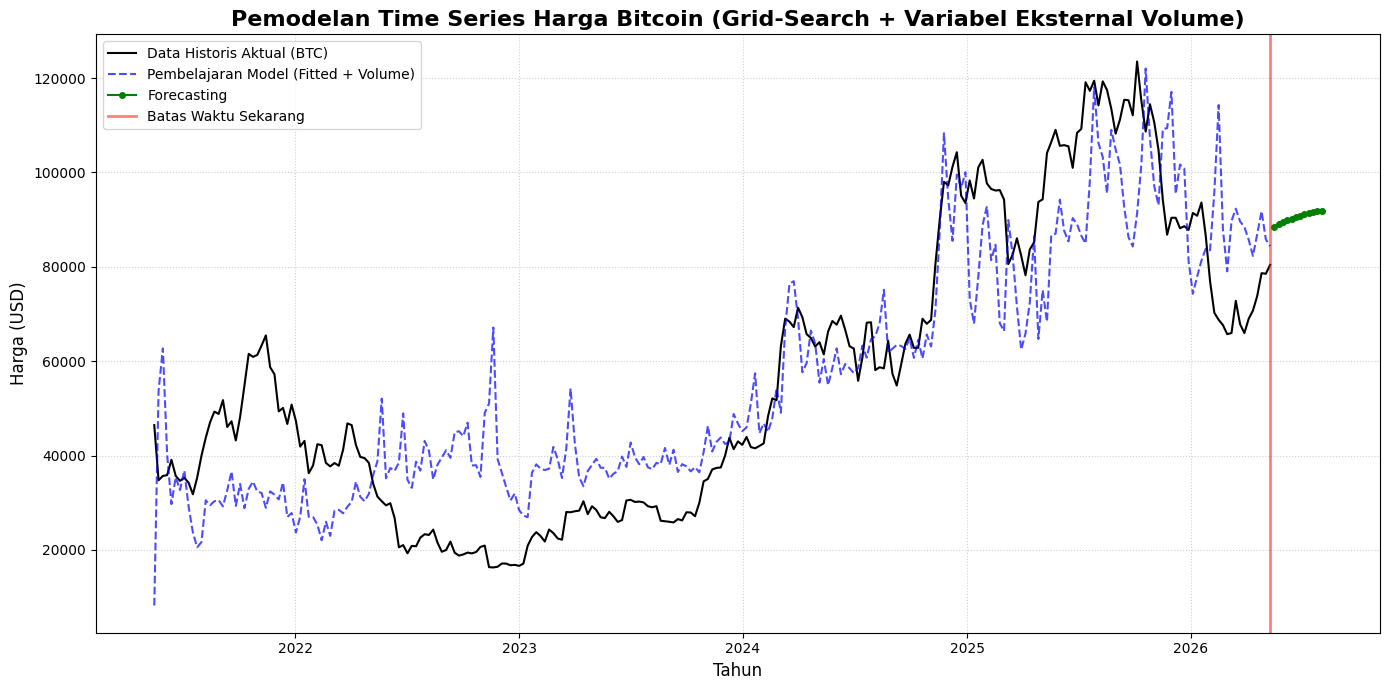

In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.deterministic import DeterministicProcess, Fourier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. PENGAMBILAN & PREPROCESSING DATA
# ==========================================
print("Mengunduh data BTC-USD...")
df = yf.download('BTC-USD', period='5y', interval='1wk')

# Resample frekuensi menjadi mingguan (W) dan forward fill jika ada nilai kosong
df = df.resample('W').ffill()

# --- PENAMBAHAN VARIABEL EKSTERNAL (VOLUME) ---
# Kita gunakan Volume minggu sebelumnya (Lag 1) untuk memprediksi harga minggu ini
df['Volume_Lag1'] = df['Volume'].shift(1)

# Hapus baris pertama karena shift(1) akan menghasilkan NaN di baris pertama
df.dropna(inplace=True) 

# ==========================================
# 2. OPTIMASI PARAMETER (GRID SEARCH) DENGAN VOLUME
# ==========================================
print("\nMulai mencari orde optimal (Grid Search)...")

ukuran_train = int(len(df) * 0.8)
y_train = df['Close'].iloc[:ukuran_train]
y_test = df['Close'].iloc[ukuran_train:]

mae_terbaik = float('inf')
kombinasi_terbaik = {'trend_order': 0, 'fourier_order': 0}
X_fitur_terbaik = None
dp_terpadu_terbaik = None

for t_order in range(1, 4):
    for f_order in range(1, 15):
        
        fourier_terms = Fourier(period=52, order=f_order)
        dp_uji = DeterministicProcess(
            index=df.index,
            constant=True,
            order=t_order,
            additional_terms=[fourier_terms],
            drop=True
        )
        
        # Buat matriks fitur dasar (Tren + Fourier)
        X_fitur_dasar = dp_uji.in_sample()
        
        # --- GABUNGKAN FITUR DASAR DENGAN VARIABEL EKSTERNAL (VOLUME LAG 1) ---
        X_fitur_uji = pd.concat([X_fitur_dasar, df['Volume_Lag1']], axis=1)
        
        X_train = X_fitur_uji.iloc[:ukuran_train]
        X_test = X_fitur_uji.iloc[ukuran_train:]
        
        model_uji = LinearRegression(fit_intercept=False)
        model_uji.fit(X_train, y_train)
        
        prediksi_uji = model_uji.predict(X_test)
        error_mae = mean_absolute_error(y_test, prediksi_uji)
        
        if error_mae < mae_terbaik:
            mae_terbaik = error_mae
            kombinasi_terbaik = {'trend_order': t_order, 'fourier_order': f_order}
            X_fitur_terbaik = X_fitur_uji
            dp_terpadu_terbaik = dp_uji

print("\n=== Hasil Optimasi Parameter (Termasuk Volume) ===")
print(f"Tren Orde Terbaik    : {kombinasi_terbaik['trend_order']}")
print(f"Fourier Orde Terbaik : {kombinasi_terbaik['fourier_order']}")
print(f"MAE Terendah         : {mae_terbaik:.2f}")

# ==========================================
# 3. PELATIHAN MODEL FINAL & FORECASTING
# ==========================================
model_final = LinearRegression(fit_intercept=False)
model_final.fit(X_fitur_terbaik, df['Close'])

horizon_masa_depan = 12

# Buat fitur Tren & Fourier untuk masa depan
X_masa_depan = dp_terpadu_terbaik.out_of_sample(steps=horizon_masa_depan)

# --- SKENARIO VARIABEL EKSTERNAL MASA DEPAN ---
# Kita asumsikan volume 12 minggu ke depan stabil di rata-rata 4 minggu terakhir
rata_rata_volume_terakhir = df['Volume_Lag1'].tail(4).mean()
X_masa_depan['Volume_Lag1'] = rata_rata_volume_terakhir

# Lakukan Prediksi
prediksi_masa_depan = model_final.predict(X_masa_depan).ravel()

df_hasil_forecast = pd.DataFrame({
    'prediksi': np.round(prediksi_masa_depan, 0)
}, index=X_masa_depan.index)

print("\n=== Hasil Forecasting (12 Minggu Kedepan) ===")
print(df_hasil_forecast)

# ==========================================
# 4. VISUALISASI KESELURUHAN
# ==========================================
plt.figure(figsize=(14, 7))

plt.plot(df.index, df['Close'], color='black', label='Data Historis Aktual (BTC)')
plt.plot(X_fitur_terbaik.index, model_final.predict(X_fitur_terbaik), 
         color='blue', linestyle='--', alpha=0.7, label='Pembelajaran Model (Fitted + Volume)')
plt.plot(df_hasil_forecast.index, df_hasil_forecast['prediksi'], 
         color='green', marker='o', markersize=4, label='Forecasting')

plt.axvline(x=df.index[-1], color='red', linestyle='-', linewidth=2, alpha=0.5, label='Batas Waktu Sekarang')

plt.title('Pemodelan Time Series Harga Bitcoin (Grid-Search + Variabel Eksternal Volume)', fontsize=16, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Harga (USD)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()